# ESS 배터리 수명 예측 — 02. Feature Engineering & 데이터 분할

Day 1 모델 설계 전략의 **피처셋 · 데이터 처리 · 분할 방식**을 코드로 구현하고, 모델 학습에 쓸 데이터셋을 확정합니다.

| Day 1 전략 | 구현 | 위치 |
|---|---|---|
| Target = `log10(cycle_life)`, 관측 창 = 초기 100 사이클 | `make_dataset()` → `log_life` | `src/features.py` |
| 핵심 피처 `log var(ΔQ₁₀₀₋₁₀)` 와 ΔQ 통계 | `delta_q_matrix()`, `dq_stats()` | `src/features.py` |
| 피처셋 F1 / F2 / F3 / F3+Policy | `FEATURE_SETS` | `src/features.py` |
| IR = 0 은 미측정 → 결측 처리 | `summary_features()` | `src/features.py` |
| Batch 1 내부 검증은 **충전 정책 단위로 분리** | `policy_holdout_split()` | `src/train.py` |
| Batch 2 는 standard / newstructure 그룹별로 보고 | `group` 컬럼 | `src/features.py` |

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.preprocess import load_processed
from src.features import (make_dataset, build_feature_table, delta_q_matrix, FEATURE_SETS, TARGET, vif)
from src.train import policy_holdout_split, policy_folds, SPLIT_ORDER

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'figure.figsize': (13, 4.5), 'font.size': 11, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
SPLIT_COLOR = {'train': '#3B6EA8', 'valid': '#7FA7D6', 'test_b2': '#D1495B', 'test_b3': '#2E9E6B'}

In [2]:
cells, summary, qd = load_processed(ROOT / 'data' / 'processed')
data = make_dataset(cells, summary, qd, n_cycles=100)
data['split'] = policy_holdout_split(data)
print(data.shape)
display(data[['cell_key', 'batch', 'group', 'policy_base', 'cycle_life', TARGET, 'split'] + FEATURE_SETS['F2']].head())

(120, 35)


,cell_key,batch,group,policy_base,cycle_life,log_life,split,dq100_10_logvar,dq100_10_skew,dq100_10_kurt
0,b1c0,1,B1,3.6C(80%)-3.6C,"1,852.000",3.268,train,-5.052,-0.727,2.064
1,b1c1,1,B1,3.6C(80%)-3.6C,"2,160.000",3.334,train,-5.136,-0.316,1.926
2,b1c2,1,B1,3.6C(80%)-3.6C,"2,237.000",3.350,train,-4.952,-0.436,1.811
3,b1c3,1,B1,4C(80%)-4C,"1,434.000",3.157,train,-4.387,-0.476,1.874
4,b1c4,1,B1,4C(80%)-4C,"1,709.000",3.233,train,-4.605,-0.349,1.635


## 1. 핵심 변수 구현 — ΔQ(V) 피처

**ISSUE** : Day 1 의 핵심 피처 `log var(ΔQ₁₀₀₋₁₀)` 와 보조 통계(skew, kurt)가 측정 노이즈 없이 올바르게 계산되는가?

,cell_key,max_spike_Ah
36,b1c41,0.072
39,b1c44,0.005
38,b1c43,0.004


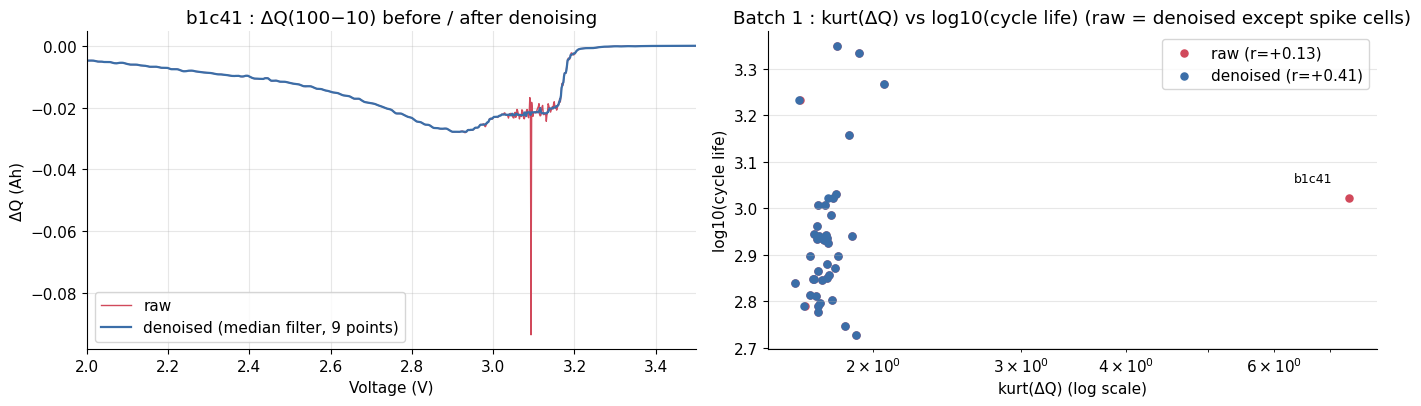

,B1,B2,B3
dq100_10_logvar,-0.95,-0.90,-0.80
dq100_10_skew,-0.58,-0.18,-0.33
dq100_10_kurt,+0.41,+0.59,+0.03
kurt_raw,+0.13,+0.59,+0.03


In [3]:
V = qd['V']
raw = delta_q_matrix(qd, 100, 10)
clean = delta_q_matrix(qd, 100, 10, denoise=True)
spike = np.abs(raw - clean).max(axis=1)
spike_df = (pd.DataFrame({'cell_key': qd['cell_keys'], 'max_spike_Ah': spike})
            .sort_values('max_spike_Ah', ascending=False).head(3))
display(spike_df)

key = spike_df.cell_key.iloc[0]; i = qd['index'][key]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(V, raw[i], color='#D1495B', lw=1, label='raw')
axes[0].plot(V, clean[i], color='#3B6EA8', lw=1.6, label='denoised (median filter, 9 points)')
axes[0].set(title=f'{key} : ΔQ(100−10) before / after denoising', xlabel='Voltage (V)', ylabel='ΔQ (Ah)', xlim=(2.0, 3.5)); axes[0].legend()

f_raw = build_feature_table(cells, summary, qd, n_cycles=100)
cmp = data[['cell_key', 'batch', TARGET, 'dq100_10_logvar', 'dq100_10_skew', 'dq100_10_kurt']].merge(
    f_raw[['cell_key', 'dq100_10_kurt']].rename(columns={'dq100_10_kurt': 'kurt_raw'}), on='cell_key')
b1 = cmp[cmp.batch == 1]
axes[1].scatter(b1.kurt_raw, b1[TARGET], color='#D1495B', s=26, label=f'raw (r={b1.kurt_raw.corr(b1[TARGET]):+.2f})')
axes[1].scatter(b1.dq100_10_kurt, b1[TARGET], color='#3B6EA8', s=26, label=f'denoised (r={b1.dq100_10_kurt.corr(b1[TARGET]):+.2f})')
k = cmp[cmp.cell_key == key].iloc[0]
axes[1].annotate(key, (k.kurt_raw, k[TARGET]), xytext=(-40, 12), textcoords='offset points', fontsize=9)
axes[1].set(xscale='log', title='Batch 1 : kurt(ΔQ) vs log10(cycle life) (raw = denoised except spike cells)', xlabel='kurt(ΔQ) (log scale)', ylabel='log10(cycle life)'); axes[1].legend()
plt.tight_layout(); plt.show()

r = pd.DataFrame({f'B{b}': g[['dq100_10_logvar', 'dq100_10_skew', 'dq100_10_kurt', 'kurt_raw']].corrwith(g[TARGET])
                  for b, g in cmp.groupby('batch')})
display(r.style.format('{:+.2f}').set_caption('ΔQ 통계 vs log10(cycle life) 상관 (denoised / raw kurt)'))

**[해석]**
- `b1c41` 의 ΔQ 곡선에는 3.1V 부근에 **폭 1점, 크기 0.07Ah 의 측정 스파이크**가 있습니다. 나머지 셀의 최대 스파이크는 0.005Ah 이하입니다.
- 이 한 점 때문에 `b1c41` 의 kurt 가 7.37 로 튀어(다른 B1 셀 1.62~2.06), Batch 1 kurt–수명 상관이 **+0.13** 으로 약해집니다.
- 전압축 9점 중앙값 필터로 스파이크만 제거하면 kurt 상관은 **+0.41** 로 회복되고, logvar(−0.95)·skew(−0.58) 는 거의 바뀌지 않습니다 → 필터가 신호는 보존하고 노이즈만 제거합니다.

> **시사점** : ΔQ 통계는 denoise 한 곡선으로 계산합니다. 41셀 소표본에서는 한 셀의 측정 오류가 선형 모델 계수를 크게 흔들 수 있기 때문입니다.

## 2. 충전 시간 피처 재검증

**ISSUE** : Day 1 에서 배치 간 부호가 일관된 측정값으로 판단한 `chargetime_mean` 이 실제로 안정적인 신호인가?

초기 100 사이클 중 충전 시간 > 60분인 사이클이 있는 셀 :


,cells,ct_max_median,ct_mean_median,ct_median_median
group,,,,
B1,3,419.790,14.886,10.764
B2-newstructure,3,"3,933.455",49.275,10.040
B2-standard,7,"3,933.623",49.423,10.177


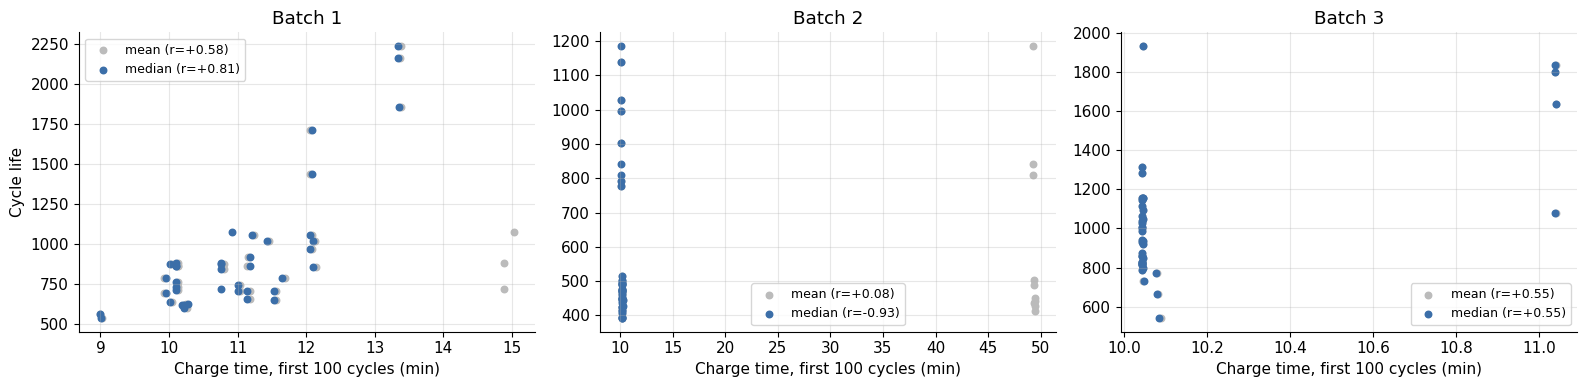

,min,median,max,std
group,,,,
B1,8.986,10.917,13.358,1.055
B2-standard,10.170,10.175,10.242,0.017
B2-newstructure,10.036,10.040,10.041,0.002
B3,10.041,10.043,11.040,0.302


In [4]:
w = summary[(summary.cycle_idx >= 1) & (summary.cycle_idx <= 100)]
ct = w.groupby('cell_key').chargetime.agg(ct_max='max', ct_mean='mean', ct_median='median').reset_index()
ct = ct.merge(data[['cell_key', 'batch', 'group']], on='cell_key')
print('초기 100 사이클 중 충전 시간 > 60분인 사이클이 있는 셀 :')
display(ct[ct.ct_max > 60].groupby('group').agg(cells=('cell_key', 'size'), ct_max_median=('ct_max', 'median'),
                                                  ct_mean_median=('ct_mean', 'median'), ct_median_median=('ct_median', 'median')))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, b in zip(axes, [1, 2, 3]):
    d = data[data.batch == b]
    ax.scatter(d.chargetime_mean, d.cycle_life, s=22, color='#BBBBBB', label=f'mean (r={d.chargetime_mean.corr(d[TARGET]):+.2f})')
    ax.scatter(d.chargetime_median, d.cycle_life, s=22, color='#3B6EA8', label=f'median (r={d.chargetime_median.corr(d[TARGET]):+.2f})')
    ax.set(title=f'Batch {b}', xlabel='Charge time, first 100 cycles (min)'); ax.legend(fontsize=9)
axes[0].set_ylabel('Cycle life')
plt.tight_layout(); plt.show()

display(data.groupby('group').chargetime_median.agg(['min', 'median', 'max', 'std']).reindex(['B1', 'B2-standard', 'B2-newstructure', 'B3']))

**[해석]**
- Batch 2 의 10개 셀은 초기 100 사이클 중 **1개 사이클의 충전 시간이 약 3,934분(65시간)**, Batch 1 의 3개 셀은 약 420분으로 기록되어 있습니다. 시험 일시정지로 생긴 시간 공백이며(Kaggle 데이터 노트 : "computer automatically restarted … time gaps"), 이 한 값 때문에 B2 셀의 평균 충전 시간이 약 10분 → 49분으로 왜곡됩니다.
- 공백에 강건한 **중앙값**으로 다시 계산하면 배치별 상관이 **B1 +0.81 / B2 −0.93 / B3 +0.55** 로 **부호가 바뀝니다.** Day 1 의 "부호 일관" 판정은 평균값의 오염 때문이었습니다.
- Batch 2·3 은 충전 시간을 약 10분으로 고정한 설계라 중앙값의 표준편차가 매우 작고(B2 10.04~10.24분), B2 의 강한 음의 상관은 standard(10.2분) vs newstructure(10.0분) **시험 구조 차이**를 반영할 뿐입니다 → 충전 시간은 사실상 **충전 정책의 대리 변수**입니다.

> **시사점 (Day 1 전략 대비 변경)** : Day 1 의 선별 원칙 ① "배치 간 부호 일관성"을 그대로 적용해 `chargetime` 을 주 피처셋 F2 에서 제외하고, 부호 불일치 피처 묶음인 F3 로 옮깁니다(중앙값 사용). **F2 = logvar, skew, kurt (ΔQ 통계 3개)** 로 확정합니다.

## 3. 결측 처리

**ISSUE** : 모델 입력 피처에 결측이 있는가? 있다면 누수 없이 어떻게 처리하는가?

In [5]:
all_feats = FEATURE_SETS['F3+Policy']
na = data.groupby('split')[all_feats].apply(lambda d: d.isna().sum()).reindex(SPLIT_ORDER)
display(na.loc[:, na.sum() > 0])
display(data[data.IR_min.isna()][['cell_key', 'group', 'split']])

,IR_min
split,
train,0
valid,0
test_b2,6
test_b3,0


,cell_key,group,split
74,b2c41,B2-standard,test_b2
75,b2c42,B2-standard,test_b2
76,b2c43,B2-newstructure,test_b2
77,b2c44,B2-newstructure,test_b2
78,b2c45,B2-newstructure,test_b2
79,b2c46,B2-standard,test_b2


**[해석]** 결측은 Batch 2 의 6개 셀에서 `IR_min` 한 피처뿐입니다. 이 셀들은 초기 100 사이클의 IR 이 모두 0(미측정)입니다.

> **처리 방침** : `IR_min` 을 쓰는 F3 계열에서만 **학습셋(train)의 중앙값으로 대체**합니다. 대체값은 모델 파이프라인 안에서 train 으로만 fit 하므로 테스트 정보가 들어가지 않습니다. 주 피처셋 F2 는 결측이 없습니다.

## 4. 데이터 분할 — 충전 정책 단위 Hold-out

**ISSUE** : 셀마다 충전 정책이 다르고 같은 정책 셀은 수명이 비슷합니다. 검증 성능에 정책 정보가 새어 들어가지 않도록 어떻게 나눌 것인가?

- **Valid (Batch 1 Hold-out)** : Batch 1 의 충전 정책을 평균 수명 순으로 정렬하고 **4개마다 1개 정책**을 valid 로 보냅니다(계통 추출). 같은 정책 셀은 항상 같은 쪽에 들어가고, valid 정책이 수명 범위 전체에 고르게 퍼집니다.
- **Train (Batch 1 CV)** : 나머지 train 셀에서 **정책 단위 5-fold CV** 로 Train 성능을 계산합니다. 정책을 평균 수명 순으로 정렬해 fold 에 번갈아 배정하므로, 같은 정책은 같은 fold 에 들어가고 sklearn 버전과 무관하게 fold 가 고정됩니다.
- **Test** : Batch 2 (필수), Batch 3 (추가 검증)

,cells,policies,life_min,life_median,life_max
split,,,,,
train,32,17,534.000,848.000,"2,237.000"
valid,9,5,617.000,788.000,"1,054.000"
test_b2,39,9,392.000,472.000,"1,186.000"
test_b3,40,8,541.000,964.500,"1,935.000"


train / valid 정책 중복 : 0
valid 정책 : ['5.4C(40%)-3.6C', '5.4C(70%)-3C', '6C(50%)-3.6C', '6C(50%)-3C', '7C(40%)-3.6C']
CV fold 크기 (cells) : [8, 9, 5, 5, 5]


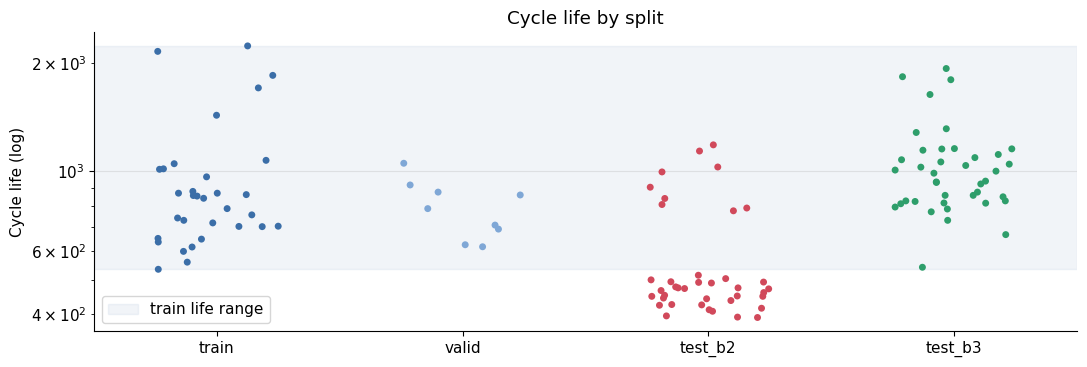

In [6]:
summary_split = (data.groupby('split')
                 .agg(cells=('cell_key', 'size'), policies=('policy_base', 'nunique'),
                      life_min=('cycle_life', 'min'), life_median=('cycle_life', 'median'), life_max=('cycle_life', 'max'))
                 .reindex(SPLIT_ORDER))
display(summary_split)

tr, va = data[data.split == 'train'], data[data.split == 'valid']
overlap = set(tr.policy_base) & set(va.policy_base)
assert not overlap, overlap
print('train / valid 정책 중복 :', len(overlap))
print('valid 정책 :', sorted(va.policy_base.unique()))

folds = policy_folds(tr, n_folds=5)
print('CV fold 크기 (cells) :', [len(v) for _, v in folds])
assert all(not set(tr.policy_base.iloc[a]) & set(tr.policy_base.iloc[b]) for a, b in folds)

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.stripplot(data=data, x='split', y='cycle_life', order=SPLIT_ORDER, palette=SPLIT_COLOR, size=5, jitter=.25, ax=ax)
ax.axhspan(tr.cycle_life.min(), tr.cycle_life.max(), color=SPLIT_COLOR['train'], alpha=.07, label='train life range')
ax.set(yscale='log', xlabel='', ylabel='Cycle life (log)', title='Cycle life by split'); ax.legend()
plt.tight_layout(); plt.show()

**[해석]**
- train 32셀(17개 정책) / valid 9셀(5개 정책, 22%) 이며, **두 집합에 겹치는 정책이 없습니다.** CV 의 각 fold 도 정책이 겹치지 않습니다.
- valid 수명(617~1,054)은 train 범위(534~2,237) 안에 고르게 분포하고, 최장·최단 정책은 train 에 남아 학습 범위를 넓게 유지합니다.
- 반면 Batch 2 는 **77%(30/39)가 train 수명 범위 아래**에 있습니다 → valid 성능은 "같은 배치 안 일반화", test 성능은 "배치 간 외삽"을 측정하므로 **Valid−Test Gap 이 클 것으로 예상**됩니다.

## 5. 피처 분포 이동 — 테스트 피처가 학습 범위 안에 있는가?

**ISSUE** : 테스트 셀의 피처 값이 train 범위를 벗어나는 정도는? (외삽이 필요한 정도 = 모델 선택의 근거)

,dq100_10_logvar,dq100_10_skew,dq100_10_kurt,F2 하나라도 범위 밖,cycle_life 범위 밖
valid,0%,0%,11%,11%,0%
B2-standard,40%,27%,17%,60%,100%
B2-newstructure,0%,22%,44%,67%,0%
test_b3,0%,8%,8%,10%,0%


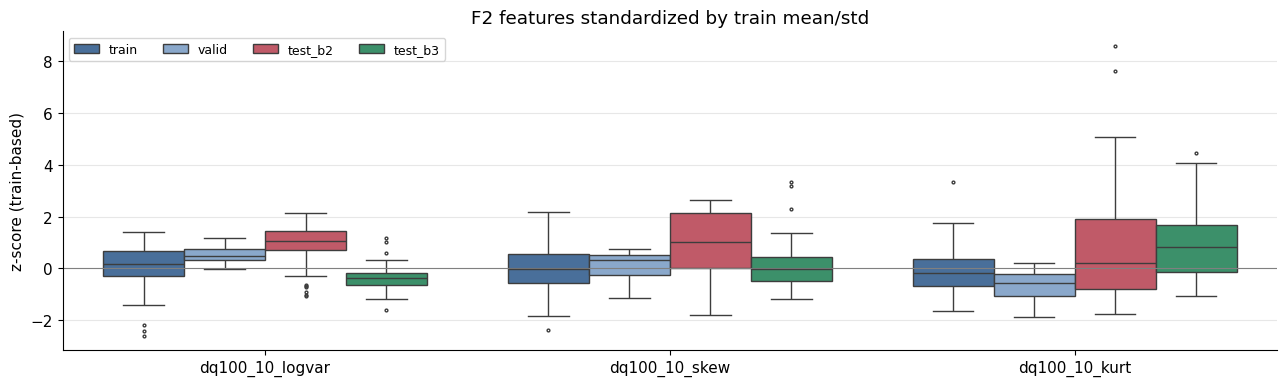

In [7]:
def out_of_range(df, ref, cols):
    lo, hi = ref[cols].min(), ref[cols].max()
    return ((df[cols] < lo) | (df[cols] > hi))

rows = {}
for name, d in [('valid', va), ('B2-standard', data[data.group == 'B2-standard']),
                ('B2-newstructure', data[data.group == 'B2-newstructure']), ('test_b3', data[data.split == 'test_b3'])]:
    o = out_of_range(d, tr, FEATURE_SETS['F2'])
    rows[name] = {**o.mean().to_dict(), 'F2 하나라도 범위 밖': o.any(axis=1).mean(),
                  'cycle_life 범위 밖': ((d.cycle_life < tr.cycle_life.min()) | (d.cycle_life > tr.cycle_life.max())).mean()}
display(pd.DataFrame(rows).T.style.format('{:.0%}').set_caption('train 범위를 벗어난 셀 비율'))

mu, sd = tr[FEATURE_SETS['F2']].mean(), tr[FEATURE_SETS['F2']].std()
z = ((data[FEATURE_SETS['F2']] - mu) / sd).assign(split=data.split).melt(id_vars='split', var_name='feature', value_name='z')
fig, ax = plt.subplots(figsize=(13, 4))
sns.boxplot(data=z, x='feature', y='z', hue='split', hue_order=SPLIT_ORDER, palette=SPLIT_COLOR, ax=ax, fliersize=2)
ax.axhline(0, c='gray', lw=.8)
ax.set(title='F2 features standardized by train mean/std', xlabel='', ylabel='z-score (train-based)'); ax.legend(ncol=4, fontsize=9)
plt.tight_layout(); plt.show()

**[해석]**
- valid 와 Batch 3 는 F2 피처가 대부분 train 범위 안에 있습니다.
- **B2-standard 는 `logvar` 의 40% 가 train 범위 위쪽**(= 더 짧은 수명 방향)에 있습니다. 수명도 100% 가 train 범위 아래입니다. Q3 에서 확인한 "피처·타깃 동시 외삽"이 분할 후에도 그대로 나타납니다.
- B2-standard 의 logvar 중앙값(−3.42)은 train 평균(−3.97)보다 약 1.2σ 높아, **피처 이동 방향이 "더 짧은 수명"과 일치합니다** → 외삽 가능한 선형 모델이면 이 이동을 짧은 수명 예측으로 이어갈 수 있습니다.
- B2-newstructure 는 kurt 의 44% 가 train 범위(1.64~2.06) 위에 있습니다. kurt 는 상관이 약한 보조 피처라, 정규화 모델에서 계수가 작게 잡히는지 03 에서 확인합니다.

> **시사점** : 테스트 성능은 외삽 능력에 좌우됩니다. 트리 모델은 train 범위 밖 피처 값을 범위 끝 값처럼 취급하므로, B2-standard 를 train 최솟값(534) 근처 이상으로 예측할 가능성이 큽니다 → Day 1 의 "선형 모델 1순위, 트리 모델 비교군" 설계를 유지합니다.

## 6. 피처셋 확정

**ISSUE** : 최종 피처셋이 train 기준으로도 다중공선성 문제가 없는가?

In [8]:
rows = []
for name, cols in FEATURE_SETS.items():
    v = vif(tr, cols)
    r_tr = tr[cols].corrwith(tr[TARGET])
    rows.append({'feature_set': name, 'n_features': len(cols), 'max_VIF (train)': v.VIF.max(),
                 'features': ', '.join(cols)})
display(pd.DataFrame(rows).set_index('feature_set'))

r = pd.DataFrame({f'B{b}': g[FEATURE_SETS['F3+Policy']].corrwith(g[TARGET]) for b, g in data.groupby('batch')})
cv = pd.DataFrame({f'B{b}': g[FEATURE_SETS['F3+Policy']].std() / g[FEATURE_SETS['F3+Policy']].mean().abs() for b, g in data.groupby('batch')})
r = r.mask(cv < .005)
r['sign_consistent'] = np.where(np.sign(r).nunique(axis=1) == 1, 'O', 'X')
display(r.style.format({c: '{:+.2f}' for c in ['B1', 'B2', 'B3']}, na_rep='고정').set_caption('배치별 상관 (log10 cycle life) · 부호 일관성'))

,n_features,max_VIF (train),features
feature_set,,,
F1,1,1.000,dq100_10_logvar
F2,3,2.103,"dq100_10_logvar, dq100_10_skew, dq100_10_kurt"
F3,8,8.186,"dq100_10_logvar, dq100_10_skew, dq100_10_kurt,..."
F3+Policy,12,393.857,"dq100_10_logvar, dq100_10_skew, dq100_10_kurt,..."


,B1,B2,B3,sign_consistent
dq100_10_logvar,-0.95,-0.90,-0.80,O
dq100_10_skew,-0.58,-0.18,-0.33,O
dq100_10_kurt,+0.41,+0.59,+0.03,O
chargetime_median,+0.81,-0.93,+0.55,X
QD_slope,+0.49,-0.36,+0.43,X
QD_max_minus_first,+0.56,-0.31,+0.01,X
IR_min,+0.34,-0.57,+0.35,X
Tavg_mean,-0.52,+0.39,-0.04,X
C_avg_0_80,-0.78,고정,고정,O
C1,-0.64,+0.20,+0.07,X


**[해석]**
- F2(ΔQ 통계 3개)는 세 배치에서 상관 부호가 모두 같고, train 기준 최대 VIF 가 **2.1** 입니다.
- F3 에 추가된 5개 피처는 모두 배치 간 부호가 바뀝니다(최대 VIF 8.2). F3+Policy 는 정책 설정값(C1, Q1, C_avg)끼리 거의 선형 관계라 최대 VIF 가 **약 394** 입니다 → 비교군으로 쓸 때는 ElasticNet 정규화가 필수입니다.

| 피처셋 | 구성 | 역할 |
|---|---|---|
| **F1** | logvar | 베이스라인 (원논문 Variance model) |
| **F2** | logvar, skew, kurt | **주 피처셋** — 배치 간 부호 일관 |
| F3 | F2 + chargetime_median, QD_slope, QD_max_minus_first, IR_min, Tavg_mean | 비교군 — 배치 과적합 확인 |
| F3+Policy | F3 + C_avg_0_80, C1, Q1, C2 | 비교군 — 정책 피처 과적합 확인 |

## 7. 모델링 데이터셋 저장

In [9]:
keep = ['cell_key', 'batch', 'group', 'policy', 'policy_base', 'split', 'cycle_life', TARGET] + FEATURE_SETS['F3+Policy']
out = ROOT / 'data' / 'processed' / 'features.parquet'
data[keep].to_parquet(out, index=False)
print(out.relative_to(ROOT), data[keep].shape)
display(data[keep].groupby('split').size().reindex(SPLIT_ORDER))

data/processed/features.parquet (120, 20)


split
train      32
valid       9
test_b2    39
test_b3    40
dtype: int64

## 요약 — 03_modeling 으로 넘기는 결정

| 항목 | 결정 | 근거 |
|---|---|---|
| Target | `log10(cycle_life)`, 예측 후 10^ŷ 로 MAPE 계산 | Day 1 Q1 |
| 주 피처셋 | **F2 = logvar, skew, kurt (denoised ΔQ)** | 1·2절 : 스파이크 보정, 충전 시간은 부호 불일치로 F3 이동 |
| 결측 | F3 계열의 `IR_min` 만 train 중앙값 대체 (파이프라인 내부) | 3절 |
| 분할 | train 32 / valid 9 (정책 단위) · train 내부 정책 단위 5-fold CV · test B2 39 / B3 40 | 4절 |
| 모델 방향 | 외삽 가능한 선형 모델 1순위, 트리 모델은 외삽 한계 비교군 | 5절 : B2-standard 피처·타깃 동시 외삽 |